In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid", palette="magma")
plt.style.use('ggplot')

np.random.seed(42)

# Load data

In [3]:
df = pd.read_csv('../dataset/star_classification_train.csv')
df.sample(5)

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID,class
54759,1.237668e+18,209.123907,17.142581,19.06475,17.67512,16.92037,16.51353,16.20790,5314,1,209,3.103014e+18,9.788856e-02,2756,54508,124,GALAXY
12456,1.237661e+18,207.692427,44.821522,22.81491,22.20049,20.46211,19.45827,19.11140,3699,3,127,7.462472e+18,5.999001e-01,6628,56366,27,GALAXY
53401,1.237674e+18,98.111949,25.395706,20.44796,18.82991,18.18723,17.84472,17.64618,6581,1,108,3.035462e+18,-1.032156e-04,2696,54167,131,STAR
62903,1.237668e+18,162.652251,23.761227,23.10796,22.21754,21.53160,22.07891,19.94902,5137,5,326,1.178595e+19,1.288676e+00,10468,58131,116,GALAXY
66338,1.237664e+18,36.798233,-0.819182,22.11652,21.02205,20.68017,20.69038,20.53773,4263,2,361,2.969003e+18,3.626223e-07,2637,54115,17,STAR


In [4]:
df.dtypes

obj_ID         float64
alpha          float64
delta          float64
u              float64
g              float64
r              float64
i              float64
z              float64
run_ID           int64
cam_col          int64
field_ID         int64
spec_obj_ID    float64
redshift       float64
plate            int64
MJD              int64
fiber_ID         int64
class           object
dtype: object

### Set data types

In [5]:
numerical_columns = df.select_dtypes(include=[np.number]).columns
df[numerical_columns] = df[numerical_columns].astype('float64')
df['class'] = df['class'].astype('category')
df.dtypes

obj_ID          float64
alpha           float64
delta           float64
u               float64
g               float64
r               float64
i               float64
z               float64
run_ID          float64
cam_col         float64
field_ID        float64
spec_obj_ID     float64
redshift        float64
plate           float64
MJD             float64
fiber_ID        float64
class          category
dtype: object

### Encode class

In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])
df['class'].value_counts()

class
0    53500
2    19434
1    17065
Name: count, dtype: int64

## Lets try making a new feature

In [7]:
X_df = pd.DataFrame(df.drop(columns='class'))
y_df = pd.DataFrame(df['class'])

X_df['intensity'] = X_df['g'] + X_df['r'] + X_df['i'] + X_df['z'] + X_df['u']

df = pd.concat([X_df, y_df], axis=1)
df['intensity'].describe()

count    89999.000000
mean       100.214922
std          8.887892
min         53.165880
25%         93.107710
50%        102.784230
75%        107.095005
max        137.714580
Name: intensity, dtype: float64

## Feature variances

In [8]:
df.var().sort_values(ascending=False)

spec_obj_ID    1.104050e+37
obj_ID         7.117499e+25
plate          8.709325e+06
run_ID         3.858441e+06
MJD            3.269721e+06
fiber_ID       7.432335e+04
field_ID       2.230953e+04
alpha          9.298353e+03
delta          3.858577e+02
intensity      7.899462e+01
u              5.059114e+00
g              4.151355e+00
r              3.439573e+00
z              3.118592e+00
i              3.088645e+00
cam_col        2.519088e+00
class          6.671203e-01
redshift       5.337513e-01
dtype: float64

### Coefficient of variance

In [9]:
def cv(x):
    return np.std(x) / np.mean(x)

# cv for each feature
df.apply(cv).sort_values(ascending=False)

class          1.314224
redshift       1.266560
delta          0.813369
field_ID       0.801112
fiber_ID       0.606948
plate          0.574270
spec_obj_ID    0.574260
alpha          0.542834
cam_col        0.451927
run_ID         0.438571
u              0.101864
g              0.098751
r              0.094398
z              0.094085
i              0.092083
intensity      0.088688
MJD            0.032528
obj_ID         0.000007
dtype: float64

### Normalization and split

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='class').values
y = df['class'].values

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

X_train.shape, X_valid.shape

((71999, 17), (18000, 17))

## Contributions to principal components

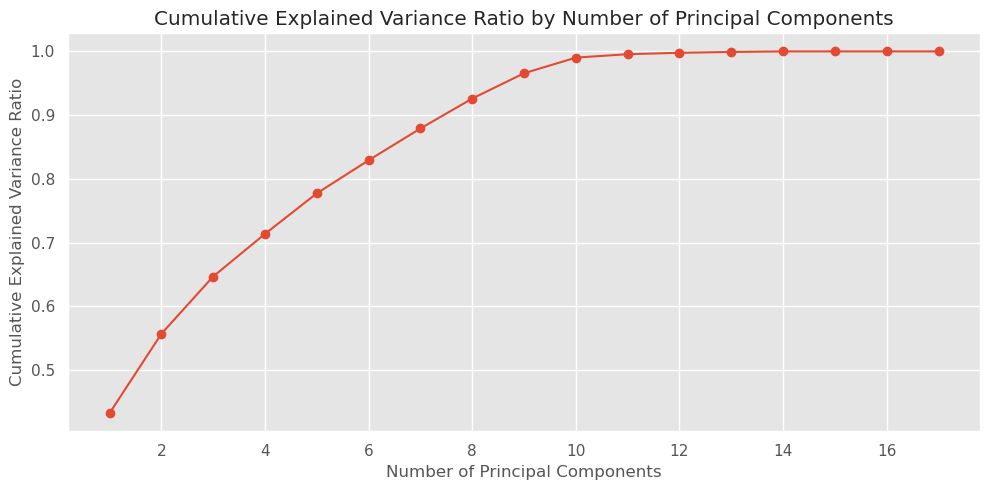

In [12]:
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()
df.iloc[:, :-1] = scaler.fit_transform(df.iloc[:, :-1])

X = df.iloc[:, :-1]
pca = PCA()
pca.fit(X)
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_explained_variance_ratio = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_explained_variance_ratio, marker='o')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Cumulative Explained Variance Ratio by Number of Principal Components')
plt.tight_layout()
plt.show()

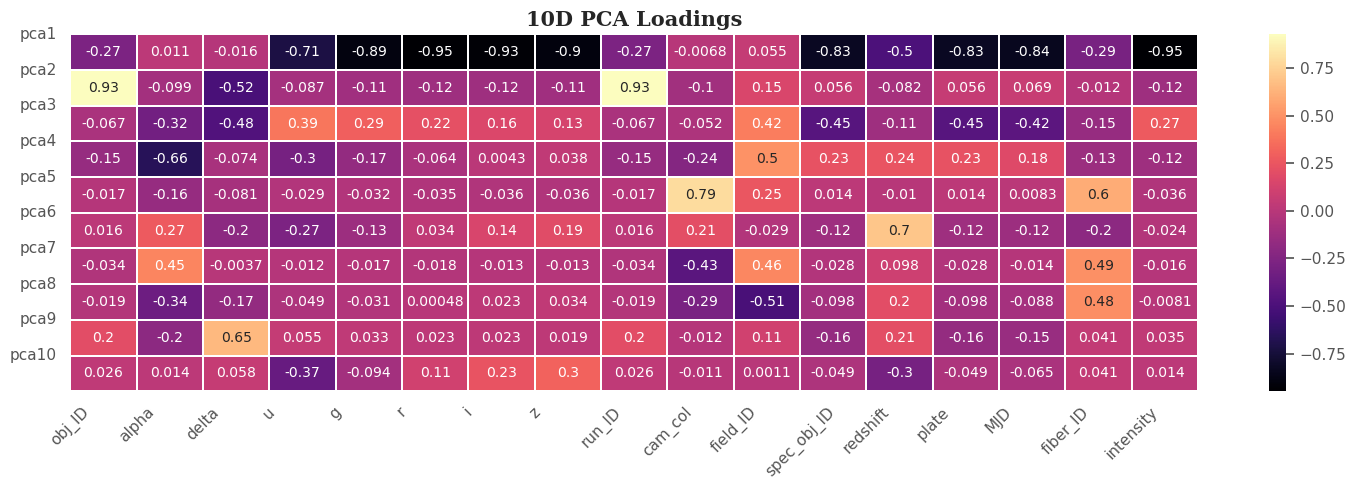

In [13]:
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)
df_pca = pd.DataFrame(X_pca, columns=['pca1', 'pca2', 'pca3', 'pca4', 'pca5', 'pca6', 'pca7', 'pca8', 'pca9', 'pca10'])
df_pca['class'] = df['class']

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(15, 5))
sns.heatmap(loadings.T, cmap='magma', annot=True, linewidths=0.1, linecolor='white')
plt.xticks(range(len(df.columns) - 1), df.columns[:-1], rotation=45)
plt.yticks(range(10), ['pca1', 'pca2', 'pca3', 'pca4', 'pca5', 'pca6', 'pca7', 'pca8', 'pca9', 'pca10'], rotation=0)
plt.title('10D PCA Loadings', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.show()

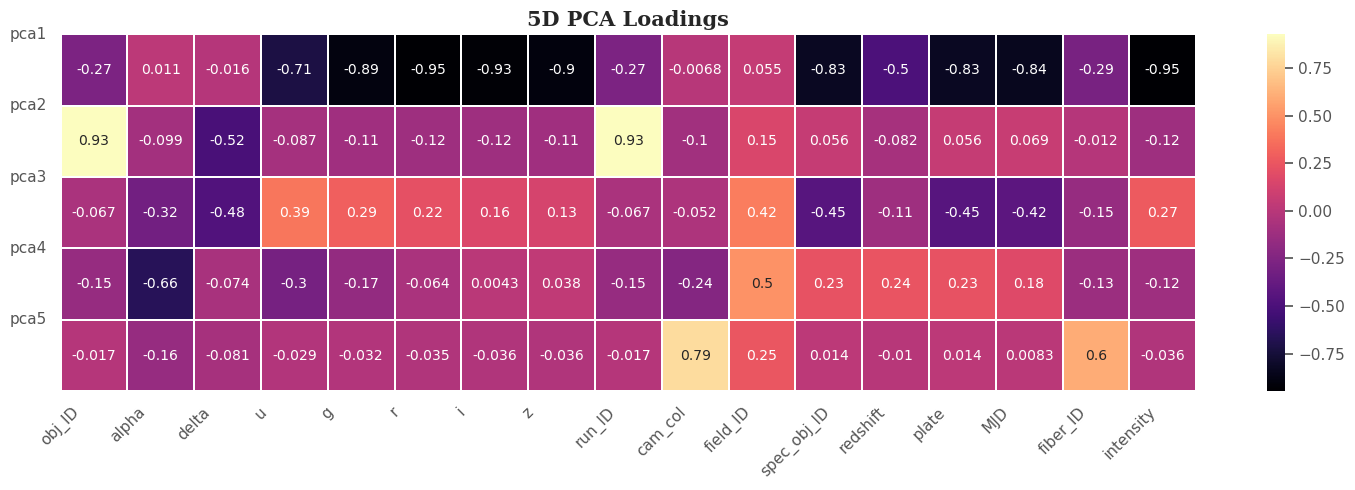

In [14]:
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)
df_pca = pd.DataFrame(X_pca, columns=['pca1', 'pca2', 'pca3', 'pca4', 'pca5'])
df_pca['class'] = df['class']

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(15, 5))
sns.heatmap(loadings.T, cmap='magma', annot=True, linewidths=0.1, linecolor='white')
plt.xticks(range(len(df.columns) - 1), df.columns[:-1], rotation=45)
plt.yticks(range(5), ['pca1', 'pca2', 'pca3', 'pca4', 'pca5'], rotation=0)
plt.title('5D PCA Loadings', fontsize=15, fontfamily='serif', fontweight='bold')
plt.tight_layout()
plt.show()

## Regularization

C=0.01, Accuracy: 0.9336111111111111
C=0.1, Accuracy: 0.9476111111111111
C=1, Accuracy: 0.9492777777777778
C=10, Accuracy: 0.9494444444444444
C=100, Accuracy: 0.9495
C=1000, Accuracy: 0.9495


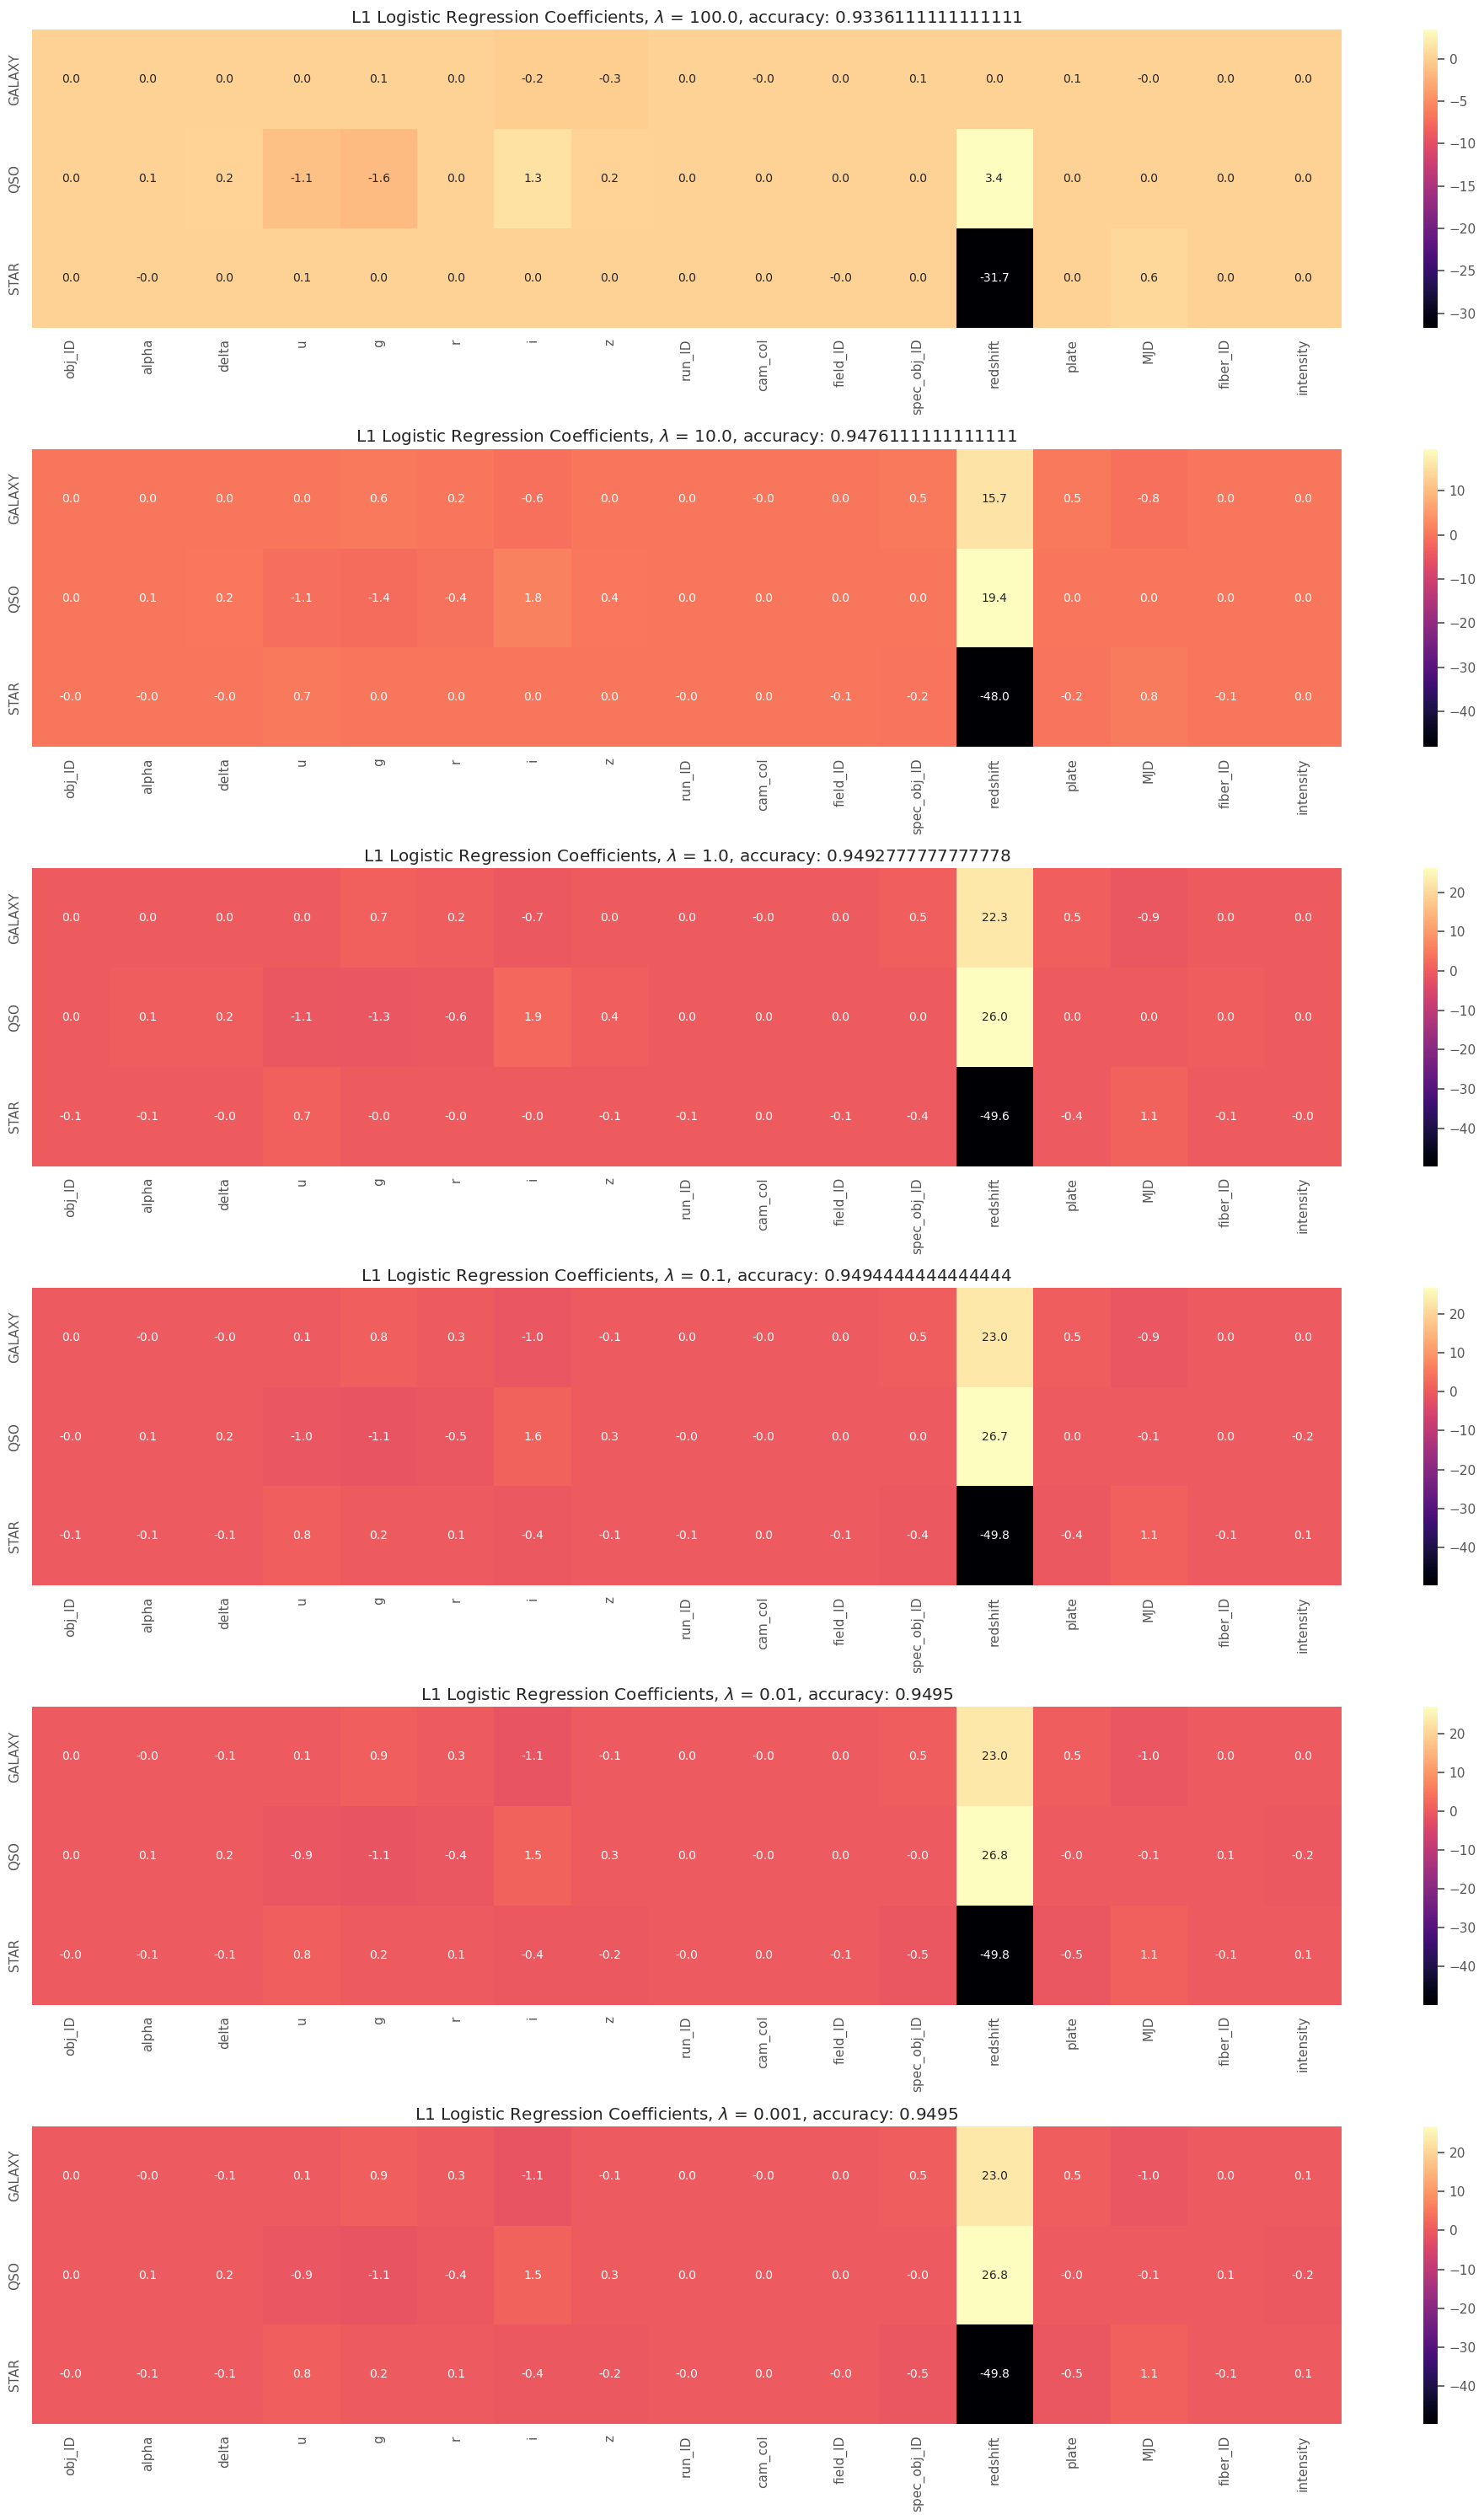

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

c_values = [0.01, 0.1, 1, 10, 100, 1000]

fig, ax = plt.subplots(len(c_values), 1, figsize=(20, 30))

for i, c in enumerate(c_values):
    lr_multinomial = LogisticRegression(penalty='l1', class_weight='balanced', C=c, solver='saga', multi_class='multinomial', random_state=42)
    lr_multinomial.fit(X_train, y_train)
    y_pred = lr_multinomial.predict(X_valid)
    print(f'C={c}, Accuracy: {accuracy_score(y_valid, y_pred)}')
    sns.heatmap(lr_multinomial.coef_, annot=True, fmt='.1f', cmap='magma', xticklabels=df.columns[:-1], yticklabels=le.classes_, ax=ax[i])
    ax[i].set_title(f'L1 Logistic Regression Coefficients, $\lambda$ = {1/c}, accuracy: {accuracy_score(y_valid, y_pred)}')
    
plt.tight_layout()
plt.show()

C=0.01, Accuracy: 0.9227222222222222
C=0.1, Accuracy: 0.9451111111111111
C=1, Accuracy: 0.9496111111111111
C=10, Accuracy: 0.9495555555555556
C=100, Accuracy: 0.9492777777777778
C=1000, Accuracy: 0.9492777777777778


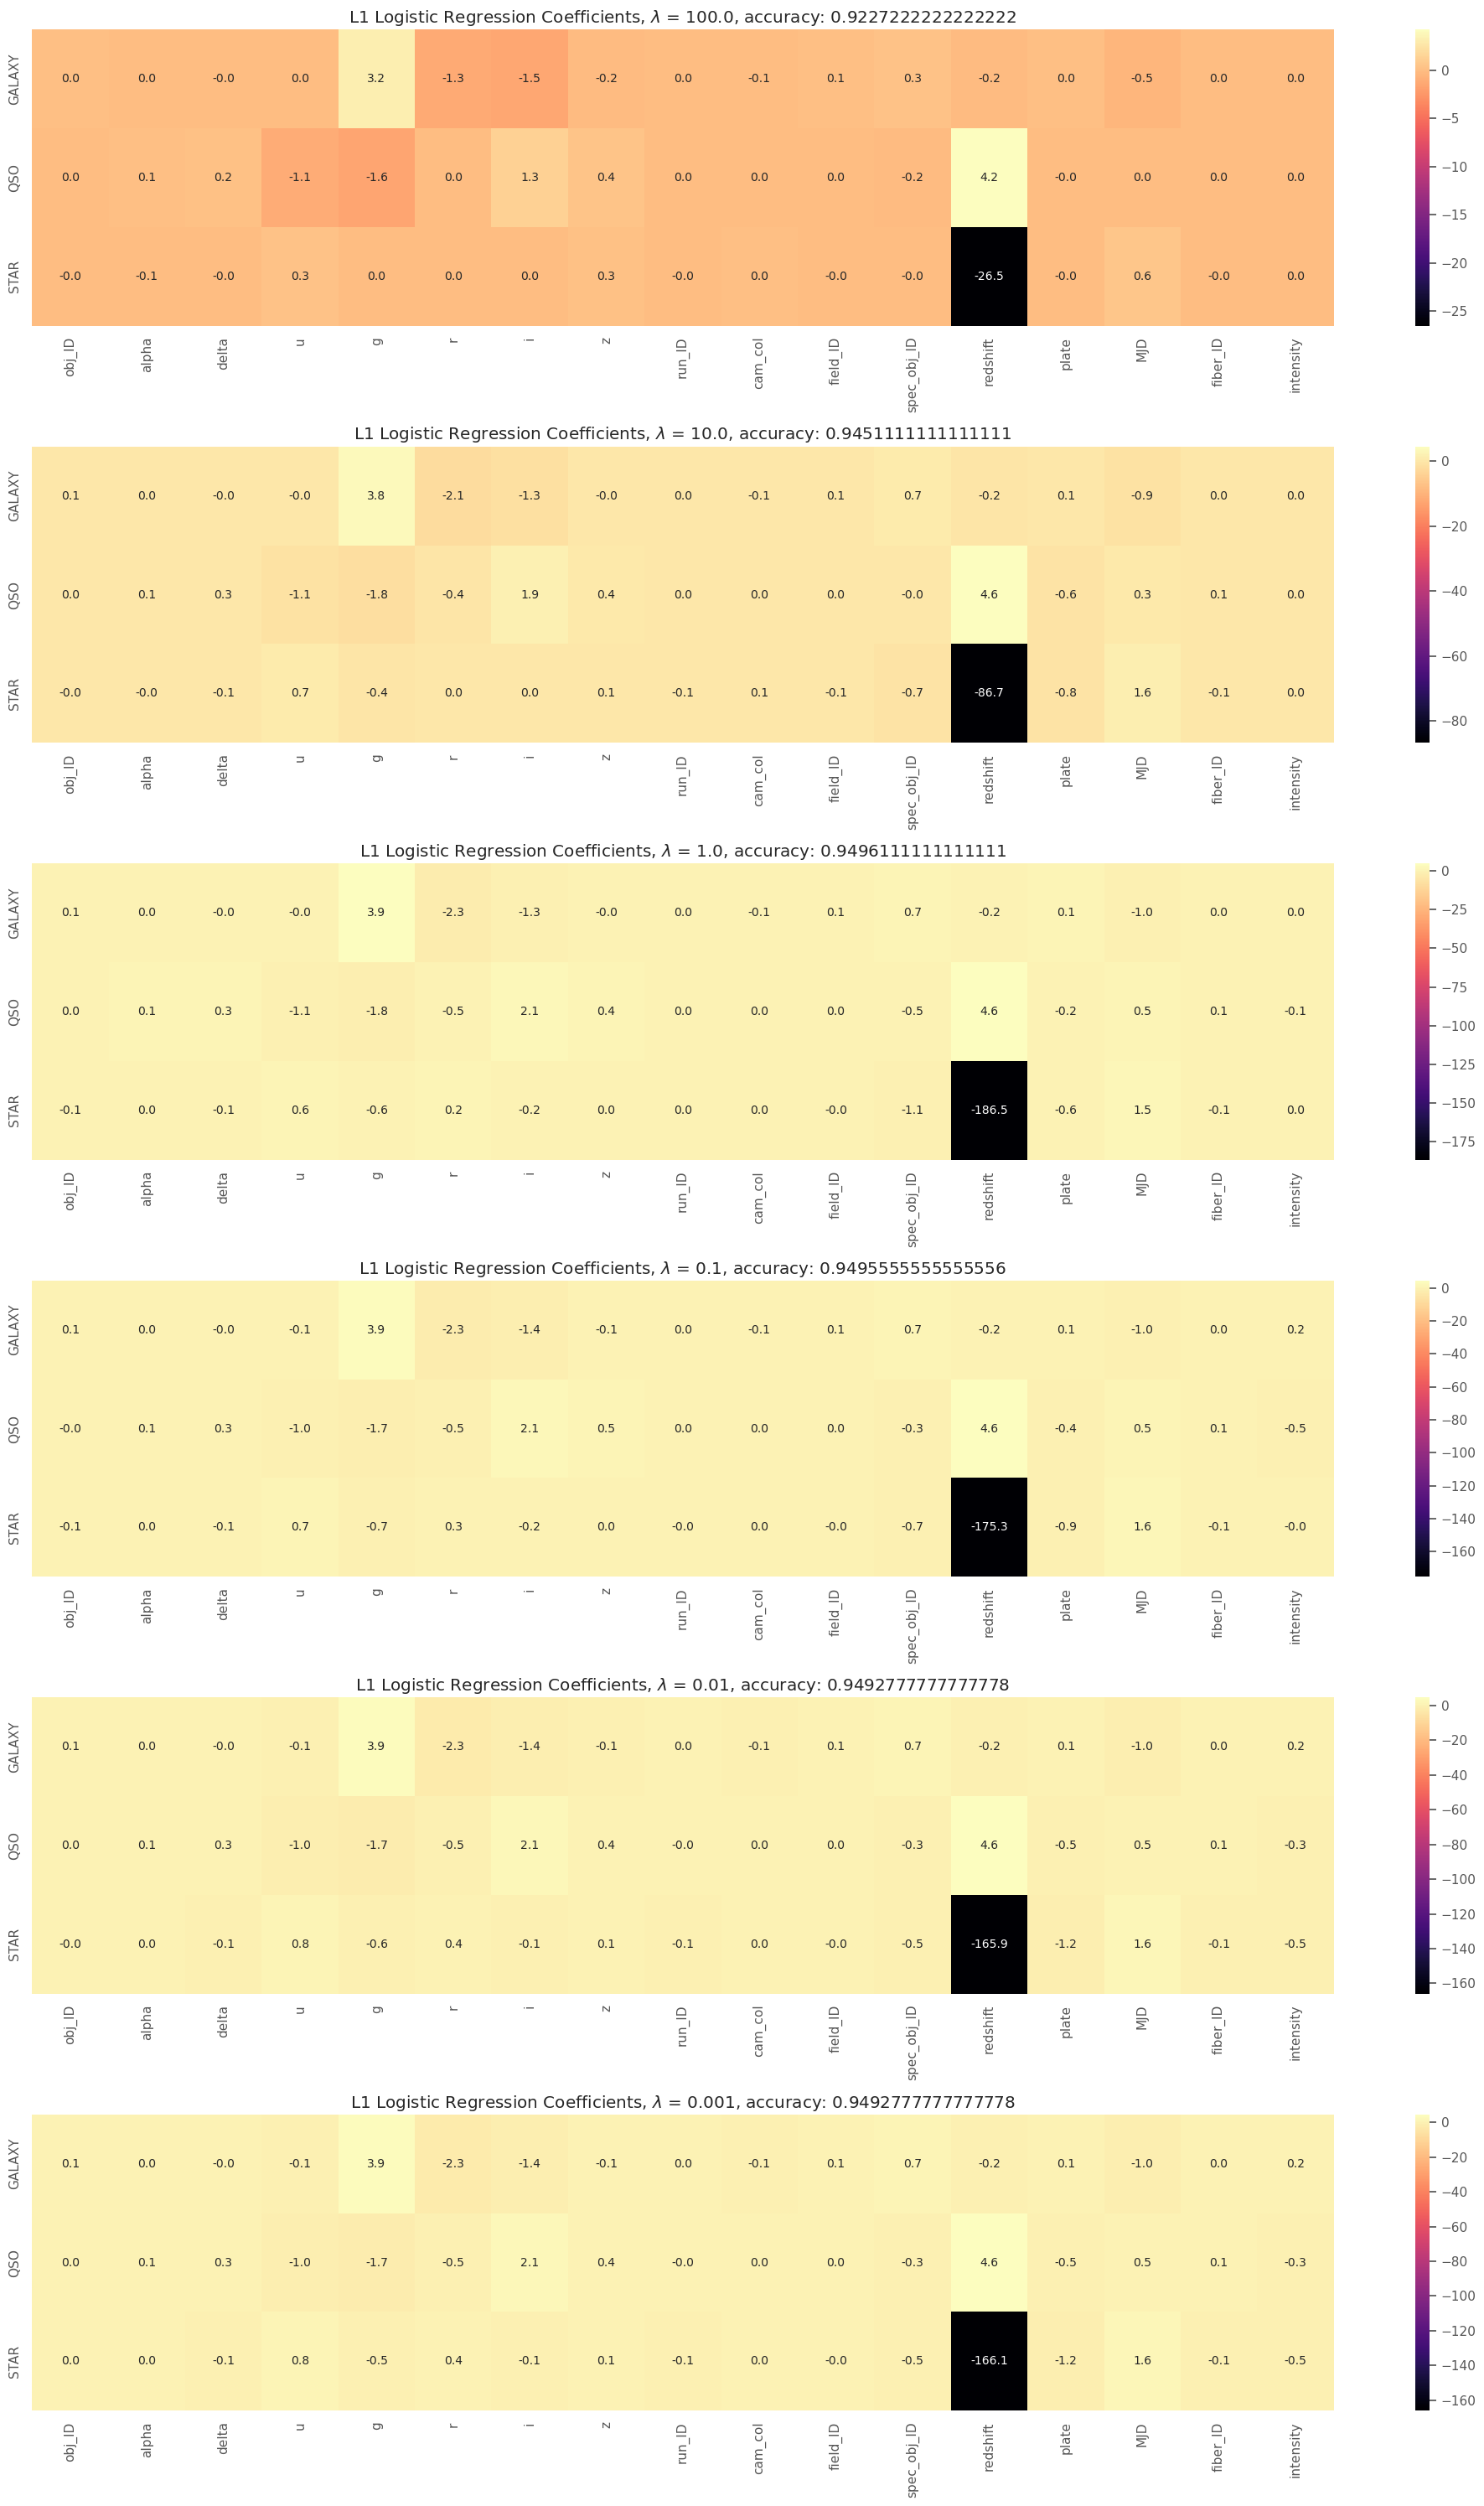

In [16]:
fig, ax = plt.subplots(len(c_values), 1, figsize=(20, 30))

for i, c in enumerate(c_values):
    lr_ovr = LogisticRegression(penalty='l1', class_weight='balanced', C=c, solver='liblinear', multi_class='ovr', random_state=42)
    lr_ovr.fit(X_train, y_train)
    y_pred = lr_ovr.predict(X_valid)
    print(f'C={c}, Accuracy: {accuracy_score(y_valid, y_pred)}')
    sns.heatmap(lr_ovr.coef_, annot=True, fmt='.1f', cmap='magma', xticklabels=df.columns[:-1], yticklabels=le.classes_, ax=ax[i])
    ax[i].set_title(f'L1 Logistic Regression Coefficients, $\lambda$ = {1/c}, accuracy: {accuracy_score(y_valid, y_pred)}')
    
plt.tight_layout()
plt.show()

Redshift has a huge impact on predictability of the class. It is the most important feature in the dataset.

## Lets explore the performance of a decision tree on the dataset with new feature

              precision    recall  f1-score   support

           0      0.969     0.970     0.970     10700
           1      0.909     0.910     0.909      3413
           2      0.998     0.994     0.996      3887

    accuracy                          0.964     18000
   macro avg      0.959     0.958     0.958     18000
weighted avg      0.964     0.964     0.964     18000



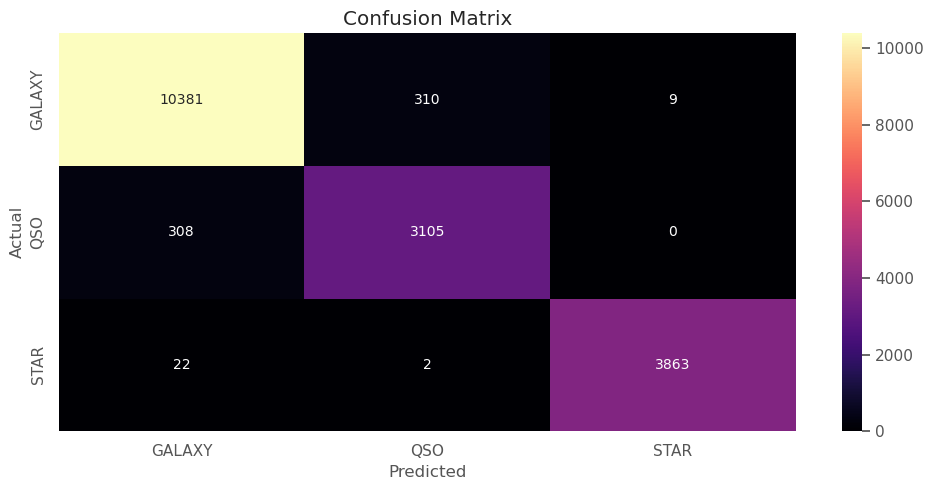

In [17]:
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

clf = tree.DecisionTreeClassifier(random_state=42)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_valid)
print(classification_report(y_valid, y_pred, digits=3))
cm = confusion_matrix(y_valid, y_pred, labels=clf.classes_)

plt.figure(figsize=(10, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

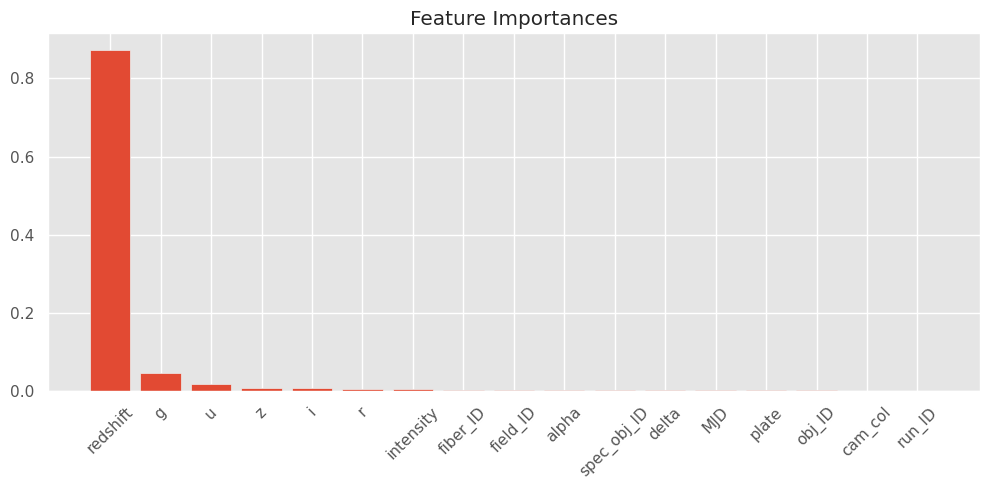

In [18]:
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.title('Feature Importances')
plt.bar(range(X_train.shape[1]), importances[indices], align='center')
plt.xticks(range(X_train.shape[1]), df.columns[:-1][indices], rotation=45)
plt.tight_layout()
plt.show()

# Grow more trees with random forest!

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_valid)
print(classification_report(y_valid, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.977     0.988     0.982     10700
           1      0.968     0.928     0.947      3413
           2      0.994     0.999     0.997      3887

    accuracy                          0.979     18000
   macro avg      0.980     0.972     0.975     18000
weighted avg      0.979     0.979     0.979     18000



In [20]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

pd.Series(importances, index=df.columns[:-1]).sort_values(ascending=False)

redshift       0.599765
z              0.076793
g              0.054888
i              0.053743
u              0.045108
spec_obj_ID    0.033497
r              0.028775
plate          0.025436
intensity      0.023959
MJD            0.017335
alpha          0.008124
delta          0.007788
obj_ID         0.006608
fiber_ID       0.005479
run_ID         0.005239
field_ID       0.005216
cam_col        0.002247
dtype: float64

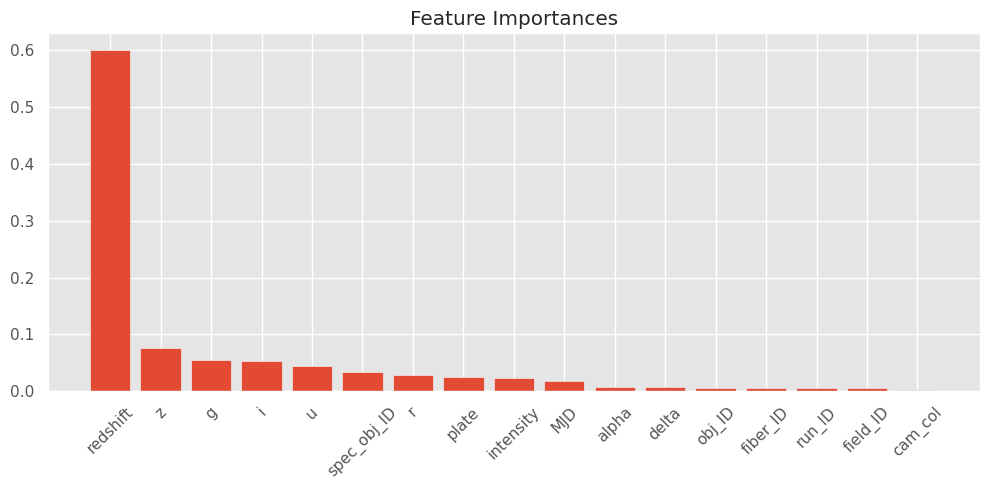

In [21]:

plt.figure(figsize=(10, 5))
plt.title('Feature Importances')
plt.bar(range(X_train.shape[1]), importances[indices], align='center')
plt.xticks(range(X_train.shape[1]), df.columns[:-1][indices], rotation=45)
plt.tight_layout()
plt.show()

## Set a treshold

In [22]:
from sklearn.feature_selection import SelectFromModel

sfm = SelectFromModel(tree.DecisionTreeClassifier(random_state=42), threshold=0.005)
sfm.fit(X_train, y_train)

selected_features = df.columns[:-1][sfm.get_support()]
selected_features

Index(['u', 'g', 'r', 'i', 'z', 'redshift'], dtype='object')

### Does it improve predictability?

              precision    recall  f1-score   support

           0      0.976     0.989     0.982     10700
           1      0.966     0.926     0.946      3413
           2      0.998     0.999     0.998      3887

    accuracy                          0.979     18000
   macro avg      0.980     0.971     0.975     18000
weighted avg      0.979     0.979     0.979     18000



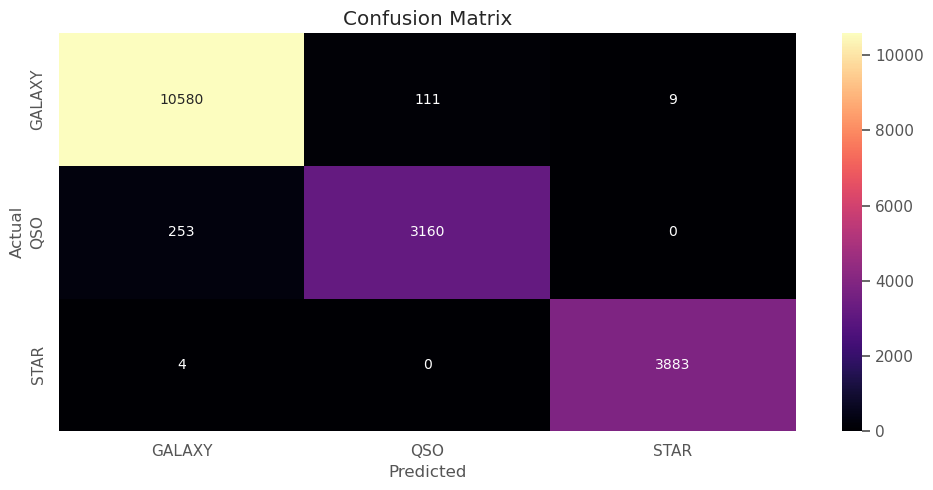

In [23]:
from sklearn.pipeline import Pipeline

clf = RandomForestClassifier(random_state=42)
sfm = SelectFromModel(tree.DecisionTreeClassifier(random_state=42), threshold=0.005)
pipeline = Pipeline(steps=[
    ('feature_selection', sfm),
    ('classifier', clf)
])

pipeline.fit(X_train, y_train.ravel())
y_pred = pipeline.predict(X_valid)
print(classification_report(y_valid, y_pred, digits=3))
cm = confusion_matrix(y_valid, y_pred, labels=clf.classes_)

plt.figure(figsize=(10, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Let's inspect the ROC curve

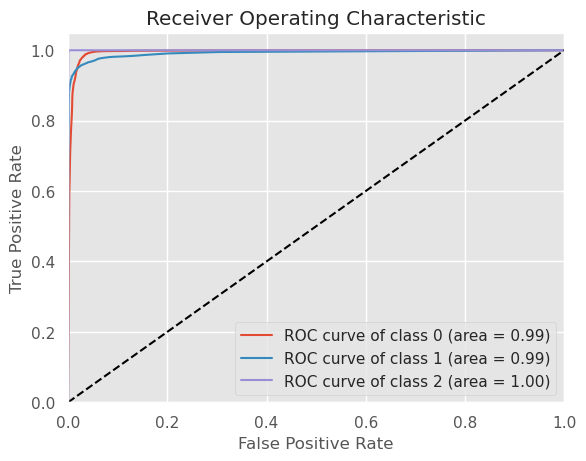

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

classes = pipeline.classes_
y_prob = pipeline.predict_proba(X_valid)
fpr = {}
tpr = {}
roc_auc = {}
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_valid == classes[i], y_prob[:,i])
    roc_auc[i] = roc_auc_score(y_valid == classes[i], y_prob[:,i])

plt.figure()
for i in range(3):
    plt.plot(fpr[i], tpr[i], label='ROC curve of class {0} (area = {1:0.2f})'.format(classes[i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower right")
plt.title('Receiver Operating Characteristic')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

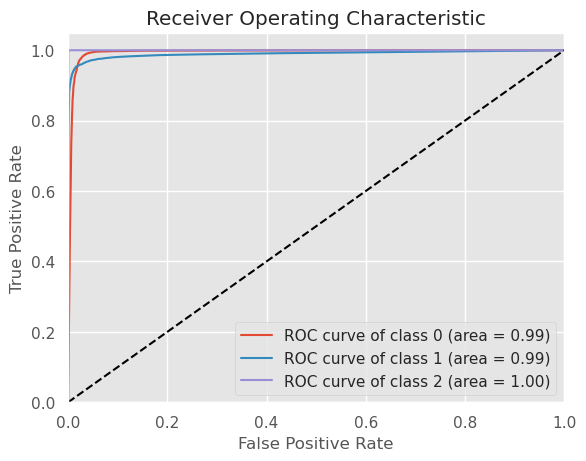

In [25]:
clf = RandomForestClassifier(n_estimators=100)
clf.fit(X_train, y_train)
classes = clf.classes_
y_prob = clf.predict_proba(X_valid)
fpr = {}
tpr = {}
roc_auc = {}
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_valid == classes[i], y_prob[:,i])
    roc_auc[i] = roc_auc_score(y_valid == classes[i], y_prob[:,i])
plt.figure()
for i in range(3):
    plt.plot(fpr[i], tpr[i], label='ROC curve of class {0} (area = {1:0.2f})'.format(classes[i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower right")
plt.title('Receiver Operating Characteristic')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()